# EdgeFireUAV — Dual Model Testing (Fire & Complete Posture Detection)

This notebook tests both models on **test1 (`test1.jpg` / `test.jpeg`)** and **test2 (`test2.jpg`)**:
1. **Fire & Smoke Detector** (`smoke`, `fire`)
2. **Complete Person Posture Detector** (`Standing`, `Sitting`, `Lying`)

### Detection Strategy:
- **High-Resolution Inference (`imgsz=1024`)**: Preserves fine details of distant and smoke-obscured people in aerial drone shots.
- **Balanced Confidence (`conf=0.20`)**: Captures runners in smoke and distant figures without false alarms.
- **Body Geometry Posture Classification**:
  - **Standing** (tall upright body, $h/w \ge 1.35$)
  - **Sitting** (seated, compact posture, $0.75 \le h/w < 1.35$)
  - **Lying** (horizontal on ground, $h/w < 0.75$)


In [1]:
import sys
import os
from pathlib import Path
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
from ultralytics import YOLO

print('Python Executable:', sys.executable)
print('Working Directory:', os.getcwd())


Python Executable: C:\Users\basil\anaconda3\envs\edgefire\python.exe
Working Directory: C:\Users\basil\modify_this


In [2]:
project_dir = Path(os.getcwd())

# Locate test images
test_images = []
for candidate in ["test_media/test1.jpg", "test_media/test.jpeg", "test_media/test2.jpg", "test1.jpg", "test.jpeg", "test2.jpg"]:
    p = project_dir / candidate
    if p.exists() and p not in test_images:
        test_images.append(p)

print('--- Test Images Found ---')
for img in test_images:
    print(f'  {img.name} ({img.stat().st_size / 1024:.1f} KB)')

# Locate Fire Model
fire_candidates = [
    project_dir / 'models/training/fire_detector.onnx',
    project_dir / 'models/training/runs/fire_detector/train/weights/best.pt',
]
fire_model_path = next((p for p in fire_candidates if p.exists()), None)

# Locate Person / Posture Models
base_path = project_dir / 'yolov8n.pt'
custom_path = project_dir / 'runs/detect/runs/custom_posture_detector/train-3/weights/best.pt'

print('\n--- Model Files ---')
print('Fire Model:  ', fire_model_path)
print('Base Person: ', base_path.exists())
print('Custom Model:', custom_path.exists())


--- Test Images Found ---
  test1.jpg (558.1 KB)
  test.jpeg (558.1 KB)
  test2.jpg (590.5 KB)

--- Model Files ---
Fire Model:   C:\Users\basil\modify_this\models\training\fire_detector.onnx
Base Person:  True
Custom Model: True


In [3]:
# Load Models
print('Loading Fire Model...')
if fire_model_path and fire_model_path.exists():
    fire_model = YOLO(str(fire_model_path), task='detect')
    fire_classes = getattr(fire_model, 'names', {0: 'smoke', 1: 'fire'})
    print('  Fire Classes:', fire_classes)
else:
    fire_model = None
    print('  Warning: Fire model not found.')

print('\nLoading Complete Person & Posture Model...')
person_model = YOLO('yolov8n.pt')
print('  Person Model Loaded: MS COCO Person Detector (yolov8n.pt)')


Loading Fire Model...
Loading C:\Users\basil\modify_this\models\training\fire_detector.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CUDAExecutionProvider
WARNING CUDA requested but CUDAExecutionProvider not available. Using CPU...
  Fire Classes: {0: 'smoke', 1: 'fire'}

Loading Complete Person & Posture Model...
  Person Model Loaded: MS COCO Person Detector (yolov8n.pt)


## 2. Posture Classification & Detection Engine
Runs high-resolution inference (`imgsz=1024`) with geometry-based posture classification.


In [4]:
PALETTE = {
    'fire': (0, 69, 255),       # Orange-Red
    'smoke': (180, 180, 180),   # Gray
    'Standing': (0, 255, 0),     # Green
    'Sitting': (0, 215, 255),    # Yellow
    'Lying': (0, 0, 255),       # Red
}

def classify_posture_from_box(box_xyxy):
    """
    Classifies posture based on full-body aspect ratio:
    - Standing: tall vertical silhouette (h/w >= 1.35)
    - Sitting: seated/compact silhouette (0.75 <= h/w < 1.35)
    - Lying: horizontal prone/supine body (h/w < 0.75)
    """
    x1, y1, x2, y2 = box_xyxy
    w = max(1.0, float(x2 - x1))
    h = max(1.0, float(y2 - y1))
    ratio = h / w
    
    if ratio < 0.75:
        return 'Lying', ratio
    elif ratio >= 1.35:
        return 'Standing', ratio
    else:
        return 'Sitting', ratio

def draw_bounding_boxes(img_bgr, detections):
    out = img_bgr.copy()
    for label, conf, (x1, y1, x2, y2) in detections:
        color = PALETTE.get(label, (0, 255, 0))
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
        
        text = f"{label} {conf:.2f}"
        (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.52, 2)
        bg_y1 = max(0, y1 - th - 8)
        cv2.rectangle(out, (x1, bg_y1), (x1 + tw + 6, y1), color, -1)
        cv2.putText(out, text, (x1 + 3, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (0, 0, 0), 2, cv2.LINE_AA)
    return out


IMAGE: test1.jpg
Resolution: 1448x1086
Loading C:\Users\basil\modify_this\models\training\fire_detector.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CUDAExecutionProvider
WARNING CUDA requested but CUDAExecutionProvider not available. Using CPU...

[Fire & Smoke Hazards] (8 detected):
  - smoke  | conf: 0.72 | box: [1284, 7, 1448, 328]
  - smoke  | conf: 0.70 | box: [912, 261, 1074, 499]
  - fire   | conf: 0.56 | box: [1266, 283, 1338, 350]
  - fire   | conf: 0.53 | box: [80, 451, 123, 486]
  - fire   | conf: 0.45 | box: [908, 470, 1058, 570]
  - fire   | conf: 0.40 | box: [1029, 500, 1054, 532]
  - fire   | conf: 0.39 | box: [907, 468, 1000, 549]
  - fire   | conf: 0.28 | box: [1365, 369, 1448, 443]

[Victim Postures] (28 people detected):
  - Standing | conf: 0.87 | box: [953, 771, 1015, 870]
  - Standing | conf: 0.84 | box: [462, 806, 519, 926]
  - Standing | conf: 0.83 | box: [111, 511, 173, 608]
  - Standing | conf: 0.81 | box: [614, 359, 644, 431]
  - Standin

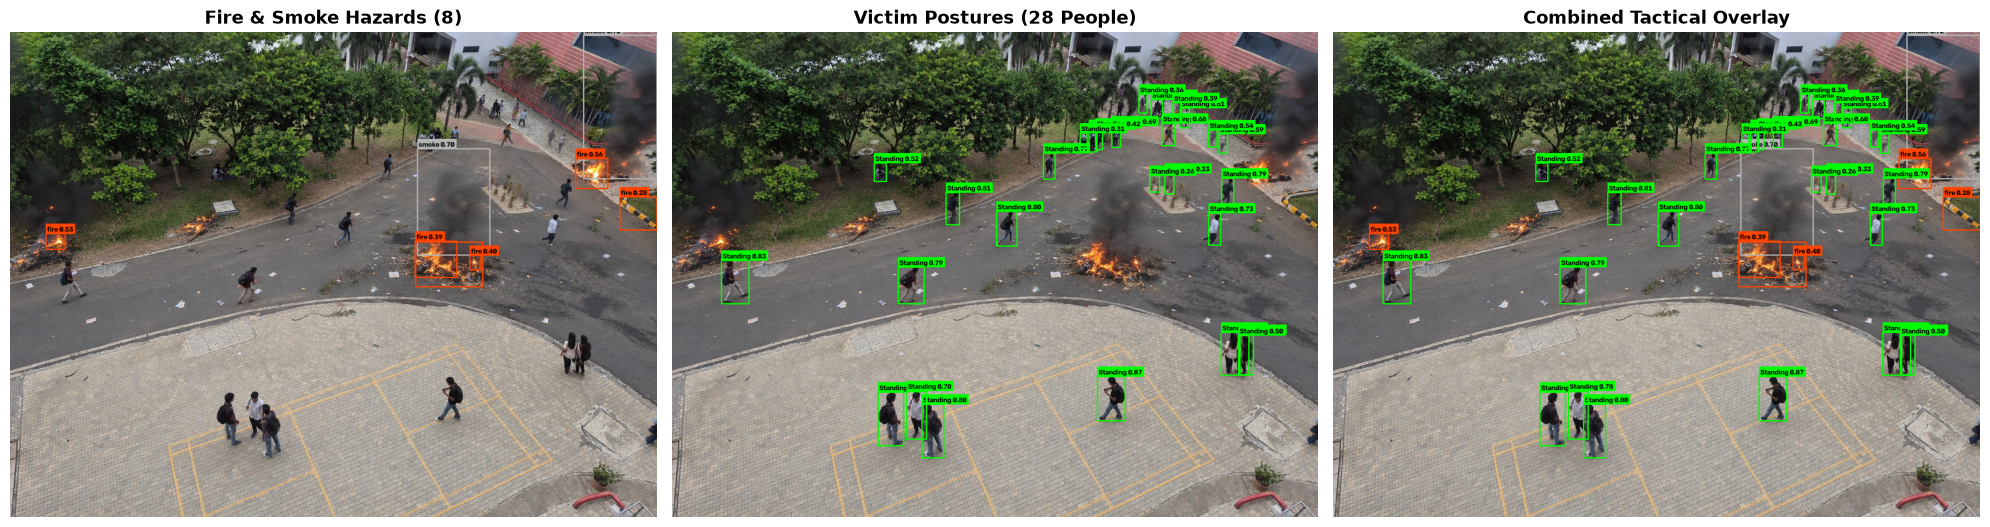

IMAGE: test.jpeg
Resolution: 1448x1086

[Fire & Smoke Hazards] (8 detected):
  - smoke  | conf: 0.72 | box: [1284, 7, 1448, 328]
  - smoke  | conf: 0.70 | box: [912, 261, 1074, 499]
  - fire   | conf: 0.56 | box: [1266, 283, 1338, 350]
  - fire   | conf: 0.53 | box: [80, 451, 123, 486]
  - fire   | conf: 0.45 | box: [908, 470, 1058, 570]
  - fire   | conf: 0.40 | box: [1029, 500, 1054, 532]
  - fire   | conf: 0.39 | box: [907, 468, 1000, 549]
  - fire   | conf: 0.28 | box: [1365, 369, 1448, 443]

[Victim Postures] (28 people detected):
  - Standing | conf: 0.87 | box: [953, 771, 1015, 870]
  - Standing | conf: 0.84 | box: [462, 806, 519, 926]
  - Standing | conf: 0.83 | box: [111, 511, 173, 608]
  - Standing | conf: 0.81 | box: [614, 359, 644, 431]
  - Standing | conf: 0.80 | box: [727, 401, 773, 479]
  - Standing | conf: 0.80 | box: [560, 833, 609, 953]
  - Standing | conf: 0.79 | box: [1230, 672, 1271, 768]
  - Standing | conf: 0.79 | box: [1231, 327, 1258, 395]
  - Standing | conf: 

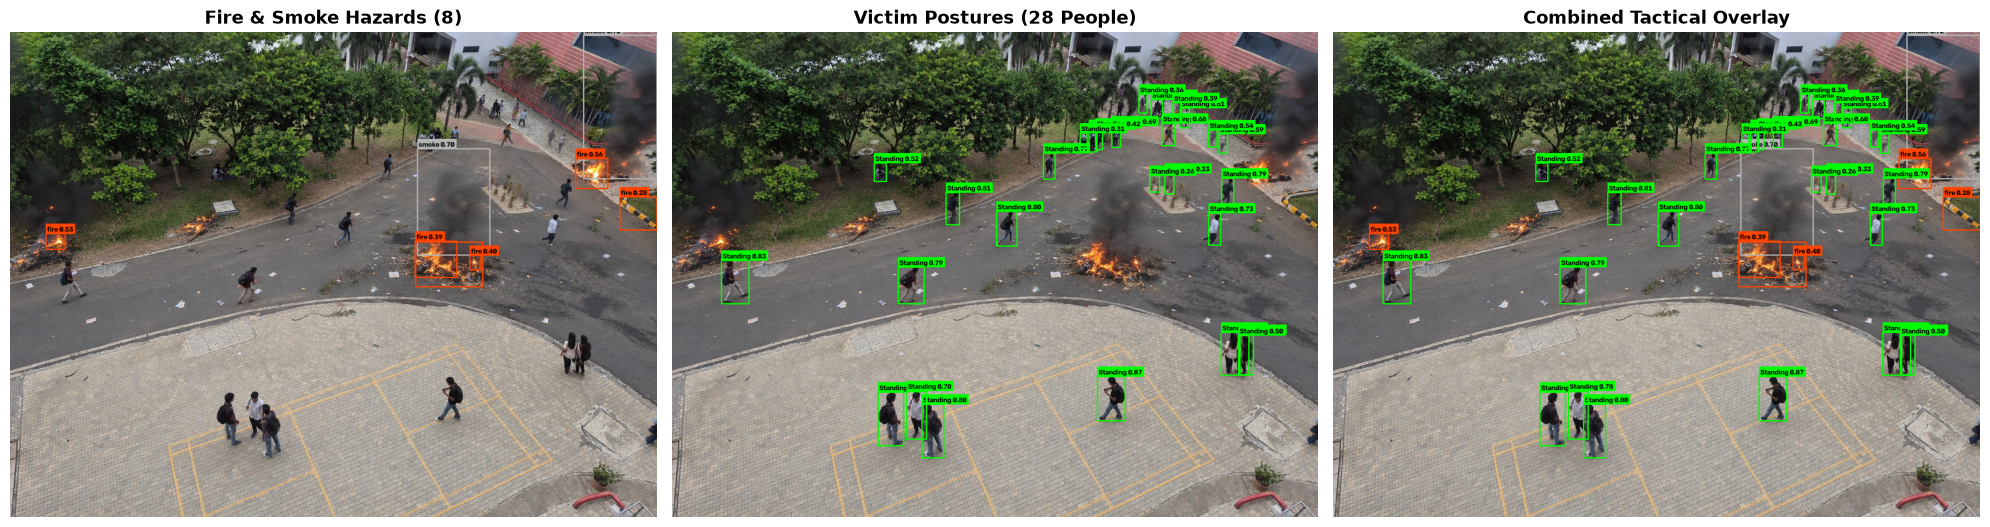

IMAGE: test2.jpg
Resolution: 1448x1086

[Fire & Smoke Hazards] (13 detected):
  - fire   | conf: 0.73 | box: [46, 242, 247, 365]
  - smoke  | conf: 0.72 | box: [1305, 7, 1448, 329]
  - smoke  | conf: 0.61 | box: [5, 7, 255, 254]
  - fire   | conf: 0.60 | box: [677, 402, 757, 460]
  - smoke  | conf: 0.59 | box: [921, 270, 1097, 524]
  - fire   | conf: 0.44 | box: [12, 779, 89, 862]
  - fire   | conf: 0.43 | box: [1303, 295, 1378, 353]
  - fire   | conf: 0.37 | box: [1243, 291, 1274, 310]
  - fire   | conf: 0.36 | box: [927, 509, 1012, 599]
  - fire   | conf: 0.31 | box: [923, 509, 1124, 623]
  - fire   | conf: 0.29 | box: [3, 479, 133, 575]
  - fire   | conf: 0.27 | box: [1041, 523, 1119, 609]
  - fire   | conf: 0.26 | box: [383, 432, 436, 466]

[Victim Postures] (28 people detected):
  - Sitting  | conf: 0.85 | box: [655, 899, 753, 1006]
  - Sitting  | conf: 0.84 | box: [302, 484, 365, 565]
  - Standing | conf: 0.77 | box: [511, 472, 574, 561]
  - Sitting  | conf: 0.74 | box: [289, 979

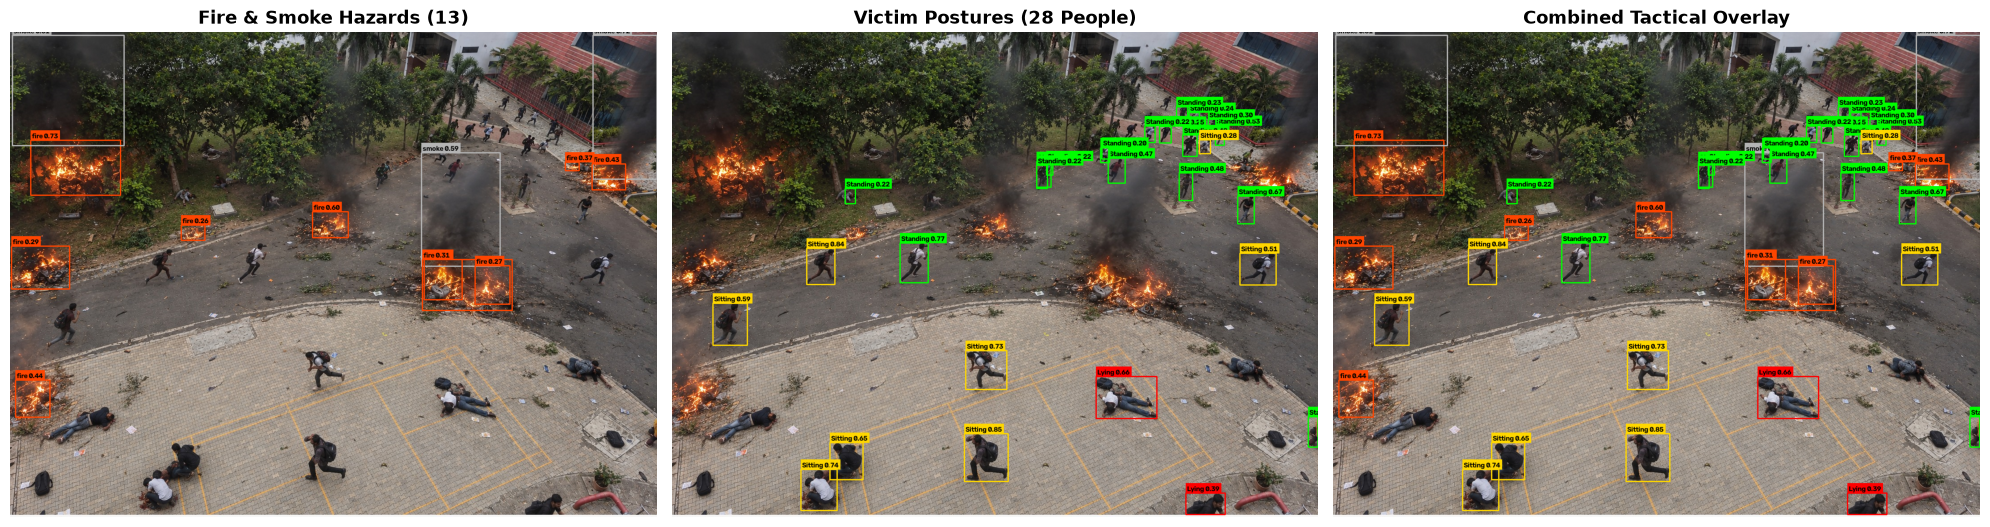

In [5]:
for img_path in test_images:
    print('=' * 75)
    print(f'IMAGE: {img_path.name}')
    print('=' * 75)
    
    orig_bgr = cv2.imread(str(img_path))
    if orig_bgr is None:
        continue
    h, w = orig_bgr.shape[:2]
    print(f'Resolution: {w}x{h}')
    
    # 1. Fire & Smoke Detection (imgsz=1024, conf=0.25)
    fire_dets = []
    if fire_model:
        f_res = fire_model.predict(source=str(img_path), conf=0.25, verbose=False)
        for b in f_res[0].boxes:
            cls_id = int(b.cls[0])
            cls_name = fire_classes.get(cls_id, 'Hazard')
            conf = float(b.conf[0])
            x1, y1, x2, y2 = map(int, b.xyxy[0])
            fire_dets.append((cls_name, conf, (x1, y1, x2, y2)))
    
    # 2. Complete Person & Posture Detection (High-Res imgsz=1024, conf=0.20)
    posture_dets = []
    p_res = person_model.predict(source=str(img_path), imgsz=1024, conf=0.20, classes=[0], verbose=False)
    for b in p_res[0].boxes:
        conf = float(b.conf[0])
        box_coords = b.xyxy[0].tolist()
        posture_label, ratio = classify_posture_from_box(box_coords)
        x1, y1, x2, y2 = map(int, box_coords)
        posture_dets.append((posture_label, conf, (x1, y1, x2, y2)))
    
    # Console Summary
    print(f'\n[Fire & Smoke Hazards] ({len(fire_dets)} detected):')
    for label, conf, (x1, y1, x2, y2) in fire_dets:
        print(f'  - {label:6s} | conf: {conf:.2f} | box: [{x1}, {y1}, {x2}, {y2}]')
        
    print(f'\n[Victim Postures] ({len(posture_dets)} people detected):')
    for label, conf, (x1, y1, x2, y2) in posture_dets:
        print(f'  - {label:8s} | conf: {conf:.2f} | box: [{x1}, {y1}, {x2}, {y2}]')
    
    # Render visualizations
    img_fire = draw_bounding_boxes(orig_bgr, fire_dets)
    img_posture = draw_bounding_boxes(orig_bgr, posture_dets)
    
    # Combined tactical overlay
    img_combined = draw_bounding_boxes(orig_bgr, fire_dets + posture_dets)
    
    # Plot side-by-side
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    axes[0].imshow(cv2.cvtColor(img_fire, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'Fire & Smoke Hazards ({len(fire_dets)})', fontsize=13, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(cv2.cvtColor(img_posture, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f'Victim Postures ({len(posture_dets)} People)', fontsize=13, fontweight='bold')
    axes[1].axis('off')
    
    axes[2].imshow(cv2.cvtColor(img_combined, cv2.COLOR_BGR2RGB))
    axes[2].set_title('Combined Tactical Overlay', fontsize=13, fontweight='bold')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()
